# EN4554 Assignment 2: Convolutional Neural Networks

**Name:** Pasidu Nethmina
**Index number:** 220424B
**GitHub profile / repository:** https://github.com/pasidunethmina/Vision-CNN-Assignment.git

**Use of AI tools:** I used Claude (Anthropic) to help write the code in this notebook and to draft the first versions of the interpretation text from my own results. I ran all experiments myself, checked the numbers in the text against my outputs, and edited the text.

---
### How this notebook is organised
| Part | Content |
|---|---|
| Setup | CIFAR-10 split (45k / 5k), per-channel normalisation with training statistics, seeds, helpers |
| Task 1 | Backpropagation from scratch (no autograd), gradient checks, MLP training, vanishing gradients |
| Task 2 | `SGD+momentum` and `Adam` as `torch.optim.Optimizer` subclasses, a 2-D toy problem, optimizer vs learning-rate study |
| Task 3 | Regularisation (incl. our own cutout and mixup) and plain vs residual networks |
| Task 4 | (Optional) best CNN with at most 500k parameters and 20 epochs, ablations, one test evaluation |

**Running it:** Colab T4 (Runtime → Change runtime type → T4 GPU) takes roughly 1.5 to 2 hours for everything.
Set `QUICK = True` in the first code cell for a few-minute dry run on any machine. It uses tiny subsets, so its numbers are meaningless.


In [1]:
import os, time, math, copy, random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from IPython.display import display

QUICK = False            # True: tiny subsets and 1-2 epochs, only to check that every cell runs
ALLOW_FAKE_DATA = False  # leave False. (Only used to test the notebook where CIFAR-10 cannot be downloaded.)
RUN_TASK4 = True         # Task 4 is optional

SEED = 0
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
print("torch", torch.__version__, "| device:", device, "| QUICK =", QUICK)

torch 2.11.0+cu130 | device: cuda | QUICK = False


## Setup: CIFAR-10
* The 50,000 training images are split into **45,000 train / 5,000 validation** with a fixed seed.
* Each channel is normalised with the **mean and std of the 45k training images only** (no information from validation or test).
* The **test set is not touched until Task 4**.
* The whole dataset is kept on the GPU as tensors, so there is no `DataLoader` overhead and augmentation can be done on the GPU.

In [2]:
def make_fake_arrays(n, seed):
    """Synthetic CIFAR-shaped data (class prototype + noise). ONLY for testing the notebook offline."""
    protos = np.random.RandomState(123).rand(10, 32, 32, 3)
    rng = np.random.RandomState(seed)
    y = rng.randint(0, 10, n)
    x = 0.35 * protos[y] + 0.65 * rng.rand(n, 32, 32, 3)
    return (x * 255).astype(np.uint8), y

def load_arrays(train=True):
    if ALLOW_FAKE_DATA:
        return make_fake_arrays(6000 if train else 1000, seed=1 if train else 2)
    ds = torchvision.datasets.CIFAR10(root="./data", train=train, download=True)
    return ds.data, np.array(ds.targets)

def to_tensor(x_uint8, y):
    return torch.from_numpy(x_uint8).permute(0, 3, 1, 2).float().div(255), torch.from_numpy(y).long()

if ALLOW_FAKE_DATA:
    print("!!! USING FAKE DATA. Results are meaningless. !!!")

x_np, y_np = load_arrays(train=True)
X_all, y_all = to_tensor(x_np, y_np)
n_val = 5000 if len(X_all) == 50000 else len(X_all) // 10
perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
tr_idx, va_idx = perm[n_val:], perm[:n_val]          # 45k train / 5k validation
X_tr, y_tr = X_all[tr_idx], y_all[tr_idx]
X_va, y_va = X_all[va_idx], y_all[va_idx]
if QUICK:
    X_tr, y_tr, X_va, y_va = X_tr[:1500], y_tr[:1500], X_va[:500], y_va[:500]

MEAN = X_tr.mean(dim=(0, 2, 3), keepdim=True)     # training statistics only
STD = X_tr.std(dim=(0, 2, 3), keepdim=True)
normalize = lambda x: (x - MEAN) / STD
X_tr, X_va = normalize(X_tr).to(device), normalize(X_va).to(device)
y_tr, y_va = y_tr.to(device), y_va.to(device)
print("train", tuple(X_tr.shape), "| val", tuple(X_va.shape))
print("channel mean:", MEAN.flatten().tolist(), "\nchannel std :", STD.flatten().tolist())
print("train class counts:", torch.bincount(y_tr).tolist())

# ---- experiment budget (full run vs. quick dry run) ----
CFG = dict(
    t1c_epochs=15, t2c_epochs=8, t3a_epochs=60, t3b_epochs=15, t4_epochs=20,
    n_small=5000, t3a_width=32, t4_batch=128,
) if not QUICK else dict(
    t1c_epochs=1, t2c_epochs=1, t3a_epochs=2, t3b_epochs=1, t4_epochs=1,
    n_small=500, t3a_width=8, t4_batch=128,
)

# ---- generic helpers shared by all tasks ----
def iterate(X, y, bs, shuffle=True, drop_last=False):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]
        if drop_last and len(j) < bs:
            break
        yield X[j], y[j]

@torch.no_grad()
def evaluate(model, X, y, bs=1000):
    model.eval()
    loss_sum, correct = 0.0, 0
    for xb, yb in iterate(X, y, bs, shuffle=False):
        out = model(xb)
        loss_sum += F.cross_entropy(out, yb, reduction="sum").item()
        correct += (out.argmax(1) == yb).sum().item()
    return loss_sum / len(X), correct / len(X)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

def moving_average(a, k):
    a = np.asarray(a, dtype=float)
    if len(a) < k:
        return a
    return np.convolve(a, np.ones(k) / k, mode="valid")

100%|██████████| 170M/170M [17:58<00:00, 158kB/s]


train (45000, 3, 32, 32) | val (5000, 3, 32, 32)
channel mean: [0.49145159125328064, 0.48206523060798645, 0.44640612602233887] 
channel std : [0.24690967798233032, 0.24345536530017853, 0.2614484429359436]
train class counts: [4489, 4490, 4494, 4491, 4498, 4528, 4500, 4530, 4500, 4480]


---
# Task 1: Backpropagation
## 1(a) Layers with explicit forward and backward passes (no autograd)
Every layer stores what it needs during `forward` and returns the gradient with respect to its input in `backward`.
For a batch of $N$ examples ($x\in\mathbb R^{N\times d_{in}}$, $W\in\mathbb R^{d_{in}\times d_{out}}$):

| Layer | Forward | Backward (given $g=\partial L/\partial \text{out}$) |
|---|---|---|
| Linear | $y = xW + b$ | $\partial L/\partial W = x^\top g,\quad \partial L/\partial b=\sum_n g_n,\quad \partial L/\partial x = gW^\top$ |
| ReLU | $y=\max(0,x)$ | $\partial L/\partial x = g\odot \mathbb 1[x>0]$ |
| Sigmoid | $y=\sigma(x)$ | $\partial L/\partial x = g\odot y(1-y)$ |
| Softmax + cross-entropy | $L=-\frac1N\sum_n \log \mathrm{softmax}(z_n)_{y_n}$ | $\partial L/\partial z = \frac1N(\mathrm{softmax}(z)-\text{onehot}(y))$ |

In [3]:
class Linear:
    def __init__(self, d_in, d_out, init="kaiming", dtype=torch.float32):
        # Kaiming (He) normal: Var = 2/fan_in (for ReLU). Xavier (Glorot): Var = 2/(fan_in+fan_out) (for sigmoid/tanh).
        var = 2.0 / d_in if init == "kaiming" else 2.0 / (d_in + d_out)
        self.W = torch.randn(d_in, d_out, dtype=dtype, device=device) * math.sqrt(var)
        self.b = torch.zeros(d_out, dtype=dtype, device=device)
    def forward(self, x):
        self.x = x
        return x @ self.W + self.b
    def backward(self, g):
        self.dW = self.x.T @ g
        self.db = g.sum(0)
        return g @ self.W.T
    def params(self): return [self.W, self.b]
    def grads(self): return [self.dW, self.db]

class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask
    def backward(self, g): return g * self.mask
    def params(self): return []
    def grads(self): return []

class Sigmoid:
    def forward(self, x):
        self.s = torch.sigmoid(x)
        return self.s
    def backward(self, g): return g * self.s * (1 - self.s)
    def params(self): return []
    def grads(self): return []

class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values          # subtract max for numerical stability
        logp = z - torch.logsumexp(z, dim=1, keepdim=True)
        self.p, self.y = logp.exp(), y
        return -logp[torch.arange(len(y)), y].mean()
    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y)), self.y] -= 1.0
        return g / len(self.y)

class MLP:
    def __init__(self, sizes, act=ReLU, init="kaiming", dtype=torch.float32):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init=init, dtype=dtype))
            if i < len(sizes) - 2:
                self.layers.append(act())
    def forward(self, x):
        for l in self.layers: x = l.forward(x)
        return x
    def backward(self, g):
        for l in reversed(self.layers): g = l.backward(g)
        return g
    def linear_layers(self): return [l for l in self.layers if isinstance(l, Linear)]
    def params(self): return [p for l in self.layers for p in l.params()]
    def grads(self): return [g for l in self.layers for g in l.grads()]

## 1(b) Gradient checks: autograd and centred finite differences
Checks are done in **float64** on a small MLP (3072-64-32-10) and 16 real training images.
* **Autograd:** the same network and loss written with `torch` ops; compared with `torch.allclose`.
* **Centred finite differences:** $\frac{L(\theta+\epsilon e_i)-L(\theta-\epsilon e_i)}{2\epsilon}$ with $\epsilon=10^{-5}$ on 25 randomly chosen coordinates per tensor (checking all 200k weights would be slow).

Relative error $=\|a-b\|/(\|a\|+\|b\|)$.

In [4]:
def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm() + 1e-30)).item()

set_seed()
dt = torch.float64
xg = X_tr[:16].reshape(16, -1).to(dt)
yg = y_tr[:16]
net = MLP([3072, 64, 32, 10], act=ReLU, dtype=dt)
ce = SoftmaxCrossEntropy()
loss_manual = ce.forward(net.forward(xg), yg)
net.backward(ce.backward())
g_manual = [g.clone() for g in net.grads()]

# (i) autograd, same parameters
ps = [p.clone().requires_grad_(True) for p in net.params()]
def forward_torch(ps):
    h = xg
    for k in range(3):
        h = h @ ps[2 * k] + ps[2 * k + 1]
        if k < 2: h = torch.relu(h)
    return F.cross_entropy(h, yg)
loss_auto = forward_torch(ps)
loss_auto.backward()
g_auto = [p.grad for p in ps]

# (ii) centred finite differences on randomly sampled coordinates
def loss_only():
    return ce.forward(net.forward(xg), yg).item()

eps, n_coord = 1e-5, 25
names = ["W1", "b1", "W2", "b2", "W3", "b3"]
rows = []
for name, p, gm, ga in zip(names, net.params(), g_manual, g_auto):
    flat_idx = torch.randperm(p.numel())[:n_coord]
    fd, an = [], []
    for k in flat_idx.tolist():
        orig = p.view(-1)[k].item()
        p.view(-1)[k] = orig + eps; lp = loss_only()
        p.view(-1)[k] = orig - eps; lm = loss_only()
        p.view(-1)[k] = orig
        fd.append((lp - lm) / (2 * eps)); an.append(gm.view(-1)[k].item())
    fd, an = torch.tensor(fd, dtype=dt), torch.tensor(an, dtype=dt)
    rows.append(dict(tensor=name, shape=tuple(p.shape),
                     rel_err_vs_autograd=rel_err(gm, ga),
                     allclose_autograd=torch.allclose(gm, ga, rtol=1e-6, atol=1e-9),
                     rel_err_vs_finite_diff=rel_err(an, fd),
                     allclose_finite_diff=torch.allclose(an, fd, rtol=1e-5, atol=1e-8)))
print(f"loss (ours) = {loss_manual.item():.12f} | loss (torch) = {loss_auto.item():.12f}")
df_gc = pd.DataFrame(rows)
pd.options.display.float_format = "{:.2e}".format
display(df_gc)
pd.options.display.float_format = None
print("ALL CHECKS PASS:", bool(df_gc.allclose_autograd.all() and df_gc.allclose_finite_diff.all()))

loss (ours) = 2.280840886305 | loss (torch) = 2.280840886305


,tensor,shape,rel_err_vs_autograd,allclose_autograd,rel_err_vs_finite_diff,allclose_finite_diff
0,W1,"(3072, 64)",0.00e+00,True,2.08e-10,True
1,b1,"(64,)",0.00e+00,True,2.53e-10,True
2,W2,"(64, 32)",0.00e+00,True,2.29e-10,True
3,b2,"(32,)",0.00e+00,True,1.01e-10,True
4,W3,"(32, 10)",0.00e+00,True,6.25e-11,True
5,b3,"(10,)",0.00e+00,True,1.11e-10,True


ALL CHECKS PASS: True


### Interpretation (1b)

The relative errors against autograd are 0 (at most about 1e-16), and against centred finite differences they are 6e-11 to 2.5e-10, so the manual backward pass is correct and every `torch.allclose` check passes. The autograd error is only float64 round-off because both compute the same exact gradient. The finite-difference error is larger because the centred difference has truncation error of order ε² (about 1e-10 for ε = 1e-5) plus round-off of order (machine epsilon)/ε. We check in float64 because in float32 the round-off (about 1e-7) divided by ε = 1e-5 would give errors around 1e-2 and hide real bugs. At a ReLU kink the function is not differentiable, so a finite difference that straddles x = 0 returns an average slope (for example 0.5) that matches neither the left slope 0 nor the right slope 1, and it disagrees with the analytic gradient.

## 1(c) Train the from-scratch MLP with SGD on flattened CIFAR-10
MLP 3072-512-256-10 with ReLU, plain minibatch SGD (we apply $W \leftarrow W-\eta\,\partial L/\partial W$ ourselves), batch size 128, $\eta=0.05$.

epoch  1/15  train loss 1.701  train acc 0.508  val acc 0.457
epoch  2/15  train loss 1.420  train acc 0.557  val acc 0.490
epoch  3/15  train loss 1.291  train acc 0.601  val acc 0.496
epoch  4/15  train loss 1.189  train acc 0.644  val acc 0.511
epoch  5/15  train loss 1.099  train acc 0.663  val acc 0.513
epoch  6/15  train loss 1.021  train acc 0.691  val acc 0.505
epoch  7/15  train loss 0.943  train acc 0.728  val acc 0.516
epoch  8/15  train loss 0.870  train acc 0.742  val acc 0.520
epoch  9/15  train loss 0.799  train acc 0.780  val acc 0.516
epoch 10/15  train loss 0.733  train acc 0.794  val acc 0.508
epoch 11/15  train loss 0.668  train acc 0.827  val acc 0.516
epoch 12/15  train loss 0.614  train acc 0.823  val acc 0.493
epoch 13/15  train loss 0.556  train acc 0.821  val acc 0.493
epoch 14/15  train loss 0.506  train acc 0.868  val acc 0.511
epoch 15/15  train loss 0.458  train acc 0.888  val acc 0.522


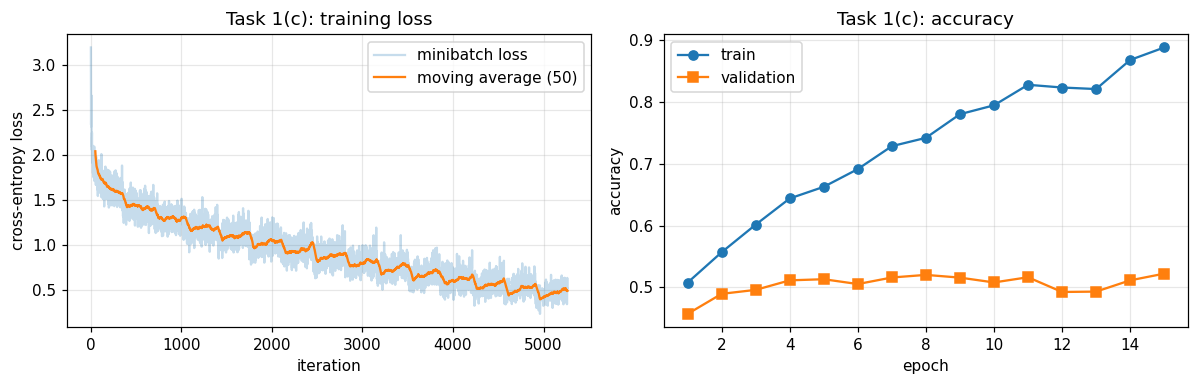

Final validation accuracy: 0.5222


In [5]:
def train_mlp(sizes, act, init, epochs, lr, bs=128, seed=SEED):
    set_seed(seed)
    mlp, crit = MLP(sizes, act=act, init=init), SoftmaxCrossEntropy()
    Xf, Xvf = X_tr.reshape(len(X_tr), -1), X_va.reshape(len(X_va), -1)
    losses, val_acc, train_acc = [], [], []
    for ep in range(epochs):
        for xb, yb in iterate(Xf, y_tr, bs, drop_last=True):
            loss = crit.forward(mlp.forward(xb), yb)
            mlp.backward(crit.backward())
            for p, g in zip(mlp.params(), mlp.grads()):
                p -= lr * g                                  # in-place SGD update
            losses.append(loss.detach())
        val_acc.append((mlp.forward(Xvf).argmax(1) == y_va).float().mean().item())
        train_acc.append((mlp.forward(Xf).argmax(1) == y_tr).float().mean().item())
        print(f"epoch {ep + 1:2d}/{epochs}  train loss {torch.stack(losses[-(len(Xf) // bs):]).mean():.3f}  "
              f"train acc {train_acc[-1]:.3f}  val acc {val_acc[-1]:.3f}")
    return mlp, torch.stack(losses).cpu().numpy(), val_acc, train_acc

mlp1, loss_curve, val_acc_curve, train_acc_curve = train_mlp([3072, 512, 256, 10], ReLU, "kaiming",
                                                              CFG["t1c_epochs"], lr=0.05)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(loss_curve, alpha=0.25, label="minibatch loss")
ax[0].plot(np.arange(len(moving_average(loss_curve, 50))) + 49, moving_average(loss_curve, 50), label="moving average (50)")
ax[0].set(xlabel="iteration", ylabel="cross-entropy loss", title="Task 1(c): training loss"); ax[0].legend()
ax[1].plot(range(1, len(val_acc_curve) + 1), train_acc_curve, "o-", label="train")
ax[1].plot(range(1, len(val_acc_curve) + 1), val_acc_curve, "s-", label="validation")
ax[1].set(xlabel="epoch", ylabel="accuracy", title="Task 1(c): accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Final validation accuracy: {val_acc_curve[-1]:.4f}")

### Interpretation (1c)

The MLP reaches 52.2% validation accuracy on raw pixels, far above chance (10%) but poor compared with the CNNs later in this report. Training accuracy keeps rising to 88.8% while validation accuracy stays at about 51 to 52% from epoch 5 onward, so the train-validation gap is about 37 points. This is overfitting: the training loss falls from 1.70 to 0.46 but the extra capacity is memorising the 45k training images. An MLP is a poor fit for images because flattening throws away the 2-D structure, and every weight is used for one pixel position only, so it has no weight sharing or translation equivariance and must learn each pattern separately at every location. It also has about 1.7M parameters in the first layer alone, which makes it easy to overfit.

## 1(d) Gradient norms across a 10-layer MLP at initialisation
10 `Linear` layers (3072→256, eight 256→256, 256→10), one batch of 256 training images, gradient norm $\|\partial L/\partial W_\ell\|_F$ per layer.
We compare sigmoid and ReLU, and, to separate the effect of the activation from the effect of the initialisation, also the mismatched pairs.
Backprop through layer $\ell$ multiplies the signal by $W_{\ell+1}^\top$ and by $\phi'(z_\ell)$. For sigmoid $\phi'\le 1/4$, for ReLU $\phi'\in\{0,1\}$.

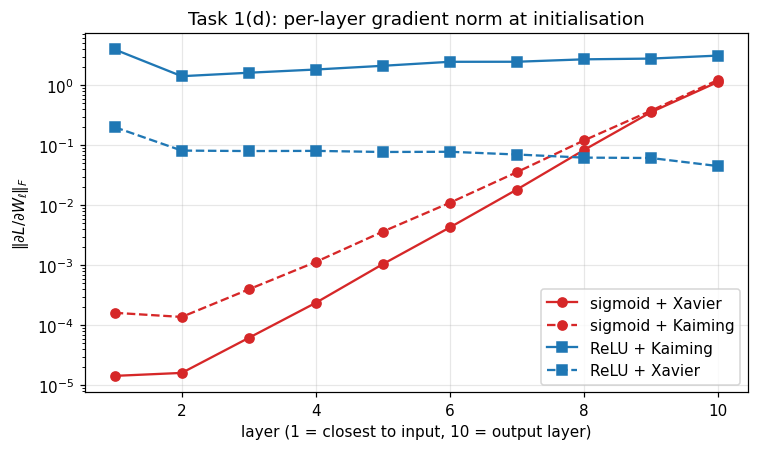

,sigmoid + Xavier,sigmoid + Kaiming,ReLU + Kaiming,ReLU + Xavier
layer 1,1.44e-05,1.62e-04,3.93e+00,2.00e-01
layer 2,1.62e-05,1.38e-04,1.41e+00,8.15e-02
layer 3,6.19e-05,3.98e-04,1.61e+00,8.01e-02
layer 4,2.38e-04,1.14e-03,1.83e+00,8.06e-02
layer 5,1.05e-03,3.64e-03,2.10e+00,7.73e-02
layer 6,4.28e-03,1.10e-02,2.45e+00,7.79e-02
layer 7,1.83e-02,3.56e-02,2.46e+00,7.01e-02
layer 8,8.31e-02,1.20e-01,2.70e+00,6.23e-02
layer 9,3.54e-01,3.75e-01,2.77e+00,6.13e-02
layer 10,1.13e+00,1.22e+00,3.11e+00,4.50e-02


ratio  (layer 10 gradient norm) / (layer 1 gradient norm):
  sigmoid + Xavier     7.84e+04
  sigmoid + Kaiming    7.53e+03
  ReLU + Kaiming          0.791
  ReLU + Xavier           0.225


In [6]:
def layer_grad_norms(act, init, depth=10, width=256, bs=256, seed=1):
    set_seed(seed)
    mlp, crit = MLP([3072] + [width] * (depth - 1) + [10], act=act, init=init), SoftmaxCrossEntropy()
    xb, yb = X_tr[:bs].reshape(bs, -1), y_tr[:bs]
    crit.forward(mlp.forward(xb), yb)
    mlp.backward(crit.backward())
    return [l.dW.norm().item() for l in mlp.linear_layers()]

runs = {"sigmoid + Xavier": (Sigmoid, "xavier"), "sigmoid + Kaiming": (Sigmoid, "kaiming"),
        "ReLU + Kaiming": (ReLU, "kaiming"), "ReLU + Xavier": (ReLU, "xavier")}
norms = {k: layer_grad_norms(*v) for k, v in runs.items()}
fig, ax = plt.subplots(figsize=(7, 4.2))
styles = {"sigmoid + Xavier": ("tab:red", "o-"), "sigmoid + Kaiming": ("tab:red", "o--"),
          "ReLU + Kaiming": ("tab:blue", "s-"), "ReLU + Xavier": ("tab:blue", "s--")}
for k, v in norms.items():
    ax.semilogy(range(1, 11), v, styles[k][1], color=styles[k][0], label=k)
ax.set(xlabel="layer (1 = closest to input, 10 = output layer)", ylabel=r"$\|\partial L/\partial W_\ell\|_F$",
       title="Task 1(d): per-layer gradient norm at initialisation")
ax.legend(); plt.tight_layout(); plt.show()
df_norm = pd.DataFrame(norms, index=[f"layer {i}" for i in range(1, 11)])
display(df_norm.style.format("{:.2e}"))
print("ratio  (layer 10 gradient norm) / (layer 1 gradient norm):")
for k, v in norms.items():
    print(f"  {k:18s} {v[-1] / v[0]:10.3g}")

### Interpretation (1d)

The sigmoid gradients vanish towards the input. With Xavier the gradient norm falls from 1.13 at layer 10 to 1.4e-5 at layer 1 (ratio 7.8e4, nearly five orders of magnitude), and with Kaiming it falls from 1.22 to 1.6e-4 (ratio 7.5e3). By the chain rule each layer multiplies the backward signal by φ'(z) and Wᵀ, and the sigmoid has φ' ≤ 0.25, so nine such layers shrink the gradient by up to about 0.25⁹ ≈ 4e-6 unless W compensates. For ReLU about half the units are active (φ' ∈ {0,1}), and He initialisation, Var(W) = 2/n, is designed to keep the signal's scale constant: ReLU + Kaiming stays almost flat (3.9 at layer 1, 3.1 at layer 10, ratio 0.79). The mismatched pairs show what matters: sigmoid + Kaiming still vanishes (only about 10× better than sigmoid + Xavier), while ReLU + Xavier does not vanish (ratio 0.225) but has a smaller overall scale. So the activation function decides whether the gradient collapses with depth, and the initialisation sets the overall scale. This is the motivation for ReLU, careful initialisation, normalisation layers and residual connections when training deep networks.

---
# Task 2: Optimizers
## 2(a) `SGD with momentum` and `Adam` as `torch.optim.Optimizer` subclasses
**SGD with momentum** (PyTorch convention): $v_{t}=\mu v_{t-1}+g_t,\qquad \theta_t=\theta_{t-1}-\eta\,v_t$ (with $\mu=0$ this is plain SGD).

**Adam** with bias correction:
$m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t,\quad v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^2,\quad
\hat m_t=\frac{m_t}{1-\beta_1^t},\ \hat v_t=\frac{v_t}{1-\beta_2^t},\quad
\theta_t=\theta_{t-1}-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$.

Both take an optional (coupled, L2-style) `weight_decay`: $g\leftarrow g+\lambda\theta$, which is what `torch.optim` does too.

In [7]:
class MySGD(torch.optim.Optimizer):
    """SGD with (optional) momentum, same convention as torch.optim.SGD (no dampening, no Nesterov)."""
    def __init__(self, params, lr=1e-2, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                if group["weight_decay"] != 0:
                    g = g.add(p, alpha=group["weight_decay"])
                if group["momentum"] != 0:
                    state = self.state[p]
                    if "velocity" not in state:
                        state["velocity"] = g.clone()                         # v_1 = g_1
                    else:
                        state["velocity"].mul_(group["momentum"]).add_(g)     # v_t = mu v_{t-1} + g_t
                    g = state["velocity"]
                p.add_(g, alpha=-group["lr"])
        return loss

class MyAdam(torch.optim.Optimizer):
    """Adam with bias correction."""
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            b1, b2 = group["betas"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g = p.grad
                if group["weight_decay"] != 0:
                    g = g.add(p, alpha=group["weight_decay"])
                state = self.state[p]
                if not state:
                    state["t"] = 0
                    state["m"] = torch.zeros_like(p)
                    state["v"] = torch.zeros_like(p)
                state["t"] += 1
                t = state["t"]
                state["m"].mul_(b1).add_(g, alpha=1 - b1)
                state["v"].mul_(b2).addcmul_(g, g, value=1 - b2)
                m_hat = state["m"] / (1 - b1 ** t)           # bias correction
                v_hat = state["v"] / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(group["eps"]), value=-group["lr"])
        return loss

**Equivalence test.** Same small network (float64), same data, 100 full-batch steps, two copies of the model: one trained with our optimizer, one with `torch.optim`.
We track the largest absolute difference between the two parameter sets over the whole run.

In [8]:
def compare_with_torch(MyOpt, TorchOpt, kwargs, steps=100):
    torch.manual_seed(0)
    base = nn.Sequential(nn.Linear(20, 16), nn.Tanh(), nn.Linear(16, 3)).double()
    m_mine, m_ref = copy.deepcopy(base), copy.deepcopy(base)
    o_mine, o_ref = MyOpt(m_mine.parameters(), **kwargs), TorchOpt(m_ref.parameters(), **kwargs)
    X = torch.randn(64, 20, dtype=torch.float64)
    y = torch.randint(0, 3, (64,))
    max_diff = 0.0
    for _ in range(steps):
        for m, o in ((m_mine, o_mine), (m_ref, o_ref)):
            o.zero_grad()
            F.cross_entropy(m(X), y).backward()
            o.step()
        max_diff = max(max_diff, max((a - b).abs().max().item() for a, b in zip(m_mine.parameters(), m_ref.parameters())))
    ok = all(torch.allclose(a, b, rtol=1e-7, atol=1e-10) for a, b in zip(m_mine.parameters(), m_ref.parameters()))
    return max_diff, ok

tests = [("SGD (momentum 0)", MySGD, torch.optim.SGD, dict(lr=0.1)),
         ("SGD momentum 0.9", MySGD, torch.optim.SGD, dict(lr=0.05, momentum=0.9)),
         ("SGD momentum 0.9 + weight decay", MySGD, torch.optim.SGD, dict(lr=0.05, momentum=0.9, weight_decay=1e-2)),
         ("Adam (defaults)", MyAdam, torch.optim.Adam, dict(lr=1e-2)),
         ("Adam + weight decay", MyAdam, torch.optim.Adam, dict(lr=1e-2, weight_decay=1e-2)),
         ("Adam (beta1=0.8, beta2=0.99, eps=1e-6)", MyAdam, torch.optim.Adam, dict(lr=1e-2, betas=(0.8, 0.99), eps=1e-6))]
rows = []
for name, mine, ref, kw in tests:
    d, ok = compare_with_torch(mine, ref, kw)
    rows.append(dict(optimizer=name, max_abs_param_diff_over_100_steps=d, torch_allclose=ok))
pd.options.display.float_format = "{:.2e}".format
display(pd.DataFrame(rows))
pd.options.display.float_format = None
print("ALL MATCH torch.optim:", all(r["torch_allclose"] for r in rows))

,optimizer,max_abs_param_diff_over_100_steps,torch_allclose
0,SGD (momentum 0),0.00e+00,True
1,SGD momentum 0.9,0.00e+00,True
2,SGD momentum 0.9 + weight decay,0.00e+00,True
3,Adam (defaults),1.91e-14,True
4,Adam + weight decay,5.08e-15,True
5,"Adam (beta1=0.8, beta2=0.99, eps=1e-6)",2.72e-15,True


ALL MATCH torch.optim: True


### Interpretation (2a)

The largest parameter differences from `torch.optim` are 0 for SGD and 2e-14 or less for Adam over 100 steps, which is float64 round-off, so our optimizers are numerically equivalent to PyTorch's. The details that matter for matching are that the first momentum step uses v₁ = g₁ (not μ·0 + (1−μ)g₁, no dampening), that weight decay is added to the gradient before the momentum update, and for Adam the bias correction m/(1−β₁ᵗ), v/(1−β₂ᵗ) and adding ε after the square root.

## 2(b) An ill-conditioned quadratic: $f(x,y)=\tfrac12(x^2+50y^2)$
The Hessian is $\mathrm{diag}(1,50)$, so the condition number is 50: the valley is steep in $y$ and shallow in $x$.
Plain gradient descent is stable only if $\eta<2/\lambda_{\max}=2/50=0.04$. Start at $(8,1)$, 60 steps each.
The learning rates below were chosen so that every method is stable and makes visible progress.

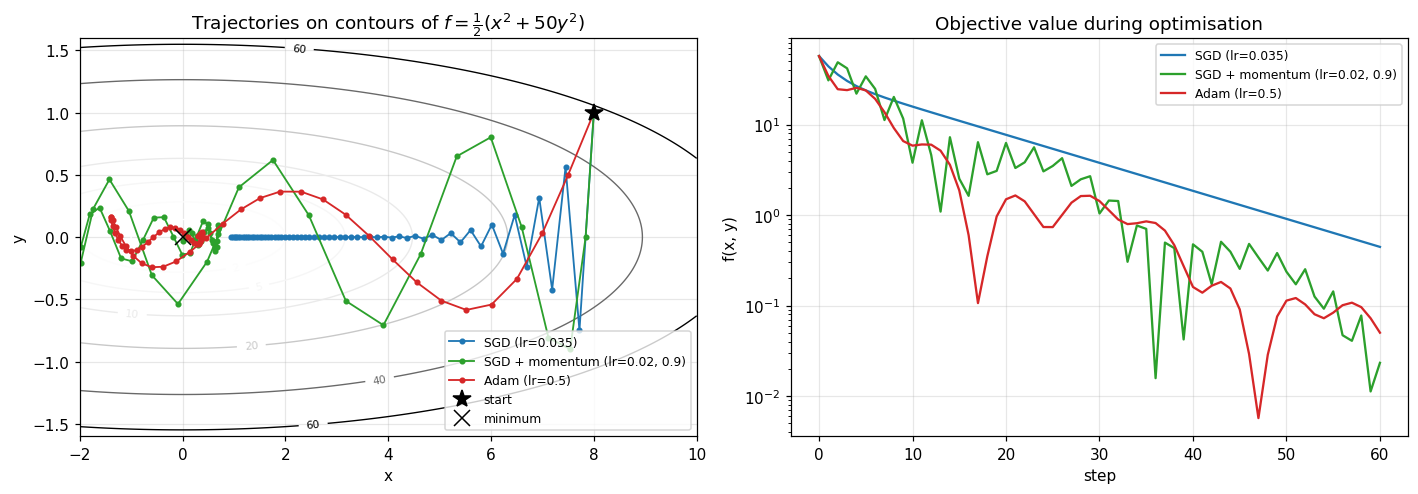

                               f_after_20  f_after_60  final_x  final_y
SGD (lr=0.035)                        7.7       0.445    0.943 3.19e-08
SGD + momentum (lr=0.02, 0.9)        6.26      0.0233   0.0116  -0.0305
Adam (lr=0.5)                        1.49      0.0502    0.307   0.0111


In [9]:
def f_quad(p):
    return 0.5 * (p[0] ** 2 + 50.0 * p[1] ** 2)

def trajectory(make_opt, start, steps):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = make_opt([p])
    pts, vals = [p.detach().numpy().copy()], [f_quad(p).item()]
    for _ in range(steps):
        opt.zero_grad()
        f_quad(p).backward()
        opt.step()
        pts.append(p.detach().numpy().copy()); vals.append(f_quad(p).item())
    return np.array(pts), np.array(vals)

START, STEPS = (8.0, 1.0), 60
methods = {
    "SGD (lr=0.035)":                lambda ps: MySGD(ps, lr=0.035),
    "SGD + momentum (lr=0.02, 0.9)": lambda ps: MySGD(ps, lr=0.02, momentum=0.9),
    "Adam (lr=0.5)":                 lambda ps: MyAdam(ps, lr=0.5),
}
trajs = {k: trajectory(mk, START, STEPS) for k, mk in methods.items()}

gx, gy = np.meshgrid(np.linspace(-2, 10, 400), np.linspace(-1.6, 1.6, 400))
gz = 0.5 * (gx ** 2 + 50 * gy ** 2)
colors = {"SGD (lr=0.035)": "tab:blue", "SGD + momentum (lr=0.02, 0.9)": "tab:green", "Adam (lr=0.5)": "tab:red"}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
cs = ax[0].contour(gx, gy, gz, levels=[0.5, 2, 5, 10, 20, 40, 60], cmap="Greys", linewidths=0.9)
ax[0].clabel(cs, inline=True, fontsize=7, fmt="%g")
for k, (pts, vals) in trajs.items():
    ax[0].plot(pts[:, 0], pts[:, 1], "o-", ms=3, lw=1.2, color=colors[k], label=k)
ax[0].plot(*START, "k*", ms=12, label="start"); ax[0].plot(0, 0, "kx", ms=10, label="minimum")
ax[0].set(xlabel="x", ylabel="y", title=r"Trajectories on contours of $f=\frac{1}{2}(x^2+50y^2)$", xlim=(-2, 10), ylim=(-1.6, 1.6))
ax[0].legend(loc="lower right", fontsize=8)
for k, (pts, vals) in trajs.items():
    ax[1].semilogy(vals + 1e-16, "-", color=colors[k], label=k)
ax[1].set(xlabel="step", ylabel="f(x, y)", title="Objective value during optimisation"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(pd.DataFrame({k: dict(f_after_20=v[20], f_after_60=v[-1], final_x=p[-1, 0], final_y=p[-1, 1])
                    for k, (p, v) in trajs.items()}).T.to_string(float_format=lambda z: f"{z:.3g}"))

### Interpretation (2b)

The function is an elongated valley (curvature 1 in x, 50 in y), and plain SGD is only stable for η < 2/50 = 0.04. With η = 0.035 the y-coordinate is multiplied by 1 − 50η = −0.75 each step, so it zig-zags across the valley, while x shrinks only by 0.965 per step, so after 60 steps SGD is still at x = 0.94 with f = 0.445. That slow progress along the shallow direction is what ill-conditioning means. SGD with momentum (lr 0.02, μ = 0.9) accumulates velocity along the consistent x direction and travels much faster, while the y components largely cancel; it overshoots and oscillates around the minimum but reaches the lowest value at step 60 (f = 0.0233). Adam divides each coordinate by √v̂, so both coordinates move by about η per step regardless of their gradient scale: its path heads diagonally towards the minimum and it is by far the fastest early (f = 1.49 at step 20, against 6.3 for momentum and 7.7 for SGD). Because its step size is fixed (η = 0.5), it keeps oscillating around the minimum and ends at f = 0.050, between momentum and SGD.

## 2(c) Small CNN, three optimizers, three learning rates each
Small CNN **without** batch norm (so the learning-rate sensitivity is not hidden by normalisation): 3 × (conv3×3 + ReLU + maxpool) with 32/64/128 channels, then FC-256 and FC-10.
All optimizers are our own implementations from 2(a); plain SGD is `MySGD(momentum=0)`. Batch size 128, no data augmentation, no schedule, same initialisation seed.
Learning-rate grids differ per optimizer (they live on different scales) but each is a factor-10 grid centred on the usual good value:
SGD $\{3\text{e-}3,3\text{e-}2,3\text{e-}1\}$, SGD+momentum $\{10^{-3},10^{-2},10^{-1}\}$, Adam $\{10^{-4},10^{-3},10^{-2}\}$.

In [10]:
def small_cnn():
    return nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(128 * 16, 256), nn.ReLU(), nn.Linear(256, 10))

def warmup_cosine(opt, total_iters, warmup_iters=0):
    """Per-iteration schedule: linear warm-up then cosine decay to 0."""
    def lam(it):
        w = min(1.0, (it + 1) / warmup_iters) if warmup_iters > 0 else 1.0
        return w * 0.5 * (1 + math.cos(math.pi * min(it, total_iters) / total_iters))
    return torch.optim.lr_scheduler.LambdaLR(opt, lam)

# ---- data augmentation / regularisation helpers (also used in Tasks 3 and 4) ----
def random_flip_crop(x, pad=4):
    """Random horizontal flip and random crop (zero padding of `pad` pixels), independently per image, on the GPU."""
    N, C, H, W = x.shape
    flip = torch.rand(N, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))
    i = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    j = torch.randint(0, 2 * pad + 1, (N,), device=x.device)
    rows = (i[:, None] + torch.arange(H, device=x.device))[:, None, :, None]
    cols = (j[:, None] + torch.arange(W, device=x.device))[:, None, None, :]
    return xp[torch.arange(N, device=x.device)[:, None, None, None], torch.arange(C, device=x.device)[None, :, None, None], rows, cols]

def cutout(x, size=16):
    """Cutout: zero a size x size square (centre uniform over the image; the square may be clipped at the border)."""
    N, C, H, W = x.shape
    cy = torch.randint(0, H, (N,), device=x.device)[:, None, None]
    cx = torch.randint(0, W, (N,), device=x.device)[:, None, None]
    ys = torch.arange(H, device=x.device)[None, :, None]
    xs = torch.arange(W, device=x.device)[None, None, :]
    hole = (ys >= cy - size // 2) & (ys < cy + size // 2) & (xs >= cx - size // 2) & (xs < cx + size // 2)
    return x * (~hole)[:, None, :, :]                 # after normalisation 0 = the dataset mean colour

def mixup_batch(x, y, alpha):
    """Mixup: x~ = lam x_i + (1-lam) x_j, with lam ~ Beta(alpha, alpha), one lam per batch; loss mixes the two label losses."""
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(len(x), device=x.device)
    return lam * x + (1 - lam) * x[perm], y, y[perm], lam

def flip_crop_cutout(x):
    return cutout(random_flip_crop(x))

def fit(model, opt, X, y, Xv, yv, epochs, bs=128, augment=None, mixup_alpha=0.0, label_smoothing=0.0,
        sched=None, eval_train=False, verbose=True, tag=""):
    """Generic training loop. `sched` (if given) is stepped once per iteration."""
    hist = dict(train_loss=[], val_loss=[], val_acc=[], train_loss_clean=[], train_acc_clean=[], diverged=False)
    t0 = time.time()
    for ep in range(epochs):
        model.train()
        run, seen = torch.zeros((), device=X.device), 0
        for xb, yb in iterate(X, y, bs, drop_last=True):
            if augment is not None:
                xb = augment(xb)
            if mixup_alpha > 0:
                xb, ya, yb2, lam = mixup_batch(xb, yb, mixup_alpha)
                out = model(xb)
                loss = lam * F.cross_entropy(out, ya, label_smoothing=label_smoothing) \
                     + (1 - lam) * F.cross_entropy(out, yb2, label_smoothing=label_smoothing)
            else:
                out = model(xb)
                loss = F.cross_entropy(out, yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            if sched is not None:
                sched.step()
            run += loss.detach() * len(xb); seen += len(xb)
        tl = (run / seen).item()
        vl, va = evaluate(model, Xv, yv)
        hist["train_loss"].append(tl); hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if eval_train:
            cl, ca = evaluate(model, X, y)
            hist["train_loss_clean"].append(cl); hist["train_acc_clean"].append(ca)
        if verbose:
            extra = f"  clean-train acc {hist['train_acc_clean'][-1]:.3f}" if eval_train else ""
            print(f"[{tag}] epoch {ep + 1:2d}/{epochs}  train loss {tl:.3f}  val loss {vl:.3f}  val acc {va:.3f}{extra}  ({time.time() - t0:.0f}s)")
        if not math.isfinite(tl):
            hist["diverged"] = True
            if verbose: print(f"[{tag}] diverged (non-finite loss), stopping this run")
            break
    return hist

OPT_GRIDS = {"SGD": [3e-3, 3e-2, 3e-1], "SGD + momentum": [1e-3, 1e-2, 1e-1], "Adam": [1e-4, 1e-3, 1e-2]}
OPT_CTORS = {"SGD": lambda ps, lr: MySGD(ps, lr=lr),
             "SGD + momentum": lambda ps, lr: MySGD(ps, lr=lr, momentum=0.9),
             "Adam": lambda ps, lr: MyAdam(ps, lr=lr)}
res2c = {}
for name, lrs in OPT_GRIDS.items():
    for lr in lrs:
        set_seed()
        model = small_cnn().to(device)
        res2c[(name, lr)] = fit(model, OPT_CTORS[name](model.parameters(), lr), X_tr, y_tr, X_va, y_va,
                                CFG["t2c_epochs"], verbose=False, tag=f"{name} lr={lr:g}")
        h = res2c[(name, lr)]
        print(f"{name:15s} lr={lr:<8g} final val acc {h['val_acc'][-1]:.4f}  final train loss {h['train_loss'][-1]:.3f}"
              + ("  [DIVERGED]" if h["diverged"] else ""))

SGD             lr=0.003    final val acc 0.3584  final train loss 1.808
SGD             lr=0.03     final val acc 0.6706  final train loss 0.929
SGD             lr=0.3      final val acc 0.7112  final train loss 0.362
SGD + momentum  lr=0.001    final val acc 0.5188  final train loss 1.299
SGD + momentum  lr=0.01     final val acc 0.7392  final train loss 0.469
SGD + momentum  lr=0.1      final val acc 0.6130  final train loss 1.056
Adam            lr=0.0001   final val acc 0.6246  final train loss 1.045
Adam            lr=0.001    final val acc 0.7586  final train loss 0.311
Adam            lr=0.01     final val acc 0.4666  final train loss 1.386


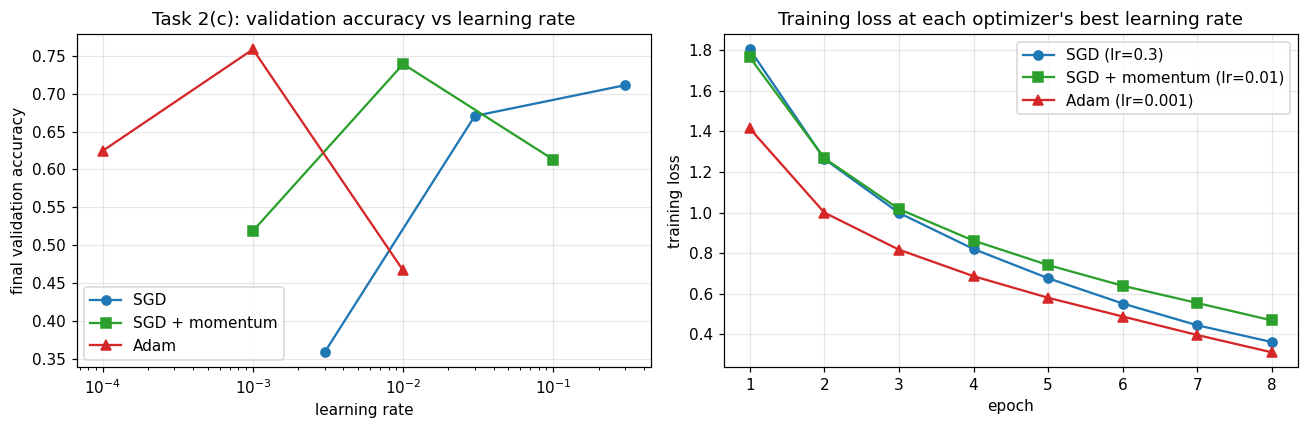

,optimizer,lr,final_val_acc,final_train_loss,diverged
0,SGD,0.003,0.3584,1.808,False
1,SGD,0.03,0.6706,0.929,False
2,SGD,0.3,0.7112,0.362,False
3,SGD + momentum,0.001,0.5188,1.299,False
4,SGD + momentum,0.01,0.7392,0.469,False
5,SGD + momentum,0.1,0.6130,1.056,False
6,Adam,0.0001,0.6246,1.045,False
7,Adam,0.001,0.7586,0.311,False
8,Adam,0.01,0.4666,1.386,False


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
mk = {"SGD": ("tab:blue", "o"), "SGD + momentum": ("tab:green", "s"), "Adam": ("tab:red", "^")}
best = {}
for name, lrs in OPT_GRIDS.items():
    accs = [res2c[(name, lr)]["val_acc"][-1] if res2c[(name, lr)]["val_acc"] else 0.1 for lr in lrs]
    ax[0].semilogx(lrs, accs, "-" + mk[name][1], color=mk[name][0], label=name)
    best[name] = lrs[int(np.argmax(accs))]
ax[0].set(xlabel="learning rate", ylabel="final validation accuracy", title="Task 2(c): validation accuracy vs learning rate")
ax[0].legend()
for name in OPT_GRIDS:
    ax[1].plot(range(1, len(res2c[(name, best[name])]["train_loss"]) + 1), res2c[(name, best[name])]["train_loss"],
               "-" + mk[name][1], color=mk[name][0], label=f"{name} (lr={best[name]:g})")
ax[1].set(xlabel="epoch", ylabel="training loss", title="Training loss at each optimizer's best learning rate"); ax[1].legend()
plt.tight_layout(); plt.show()
rows = [dict(optimizer=n, lr=lr, final_val_acc=res2c[(n, lr)]["val_acc"][-1], final_train_loss=res2c[(n, lr)]["train_loss"][-1],
             diverged=res2c[(n, lr)]["diverged"]) for n, lrs in OPT_GRIDS.items() for lr in lrs]
display(pd.DataFrame(rows).style.format({"lr": "{:g}", "final_val_acc": "{:.4f}", "final_train_loss": "{:.3f}"}))

### Interpretation (2c)

Adam with lr = 1e-3 is best at 75.9% validation accuracy, followed by SGD + momentum at lr = 0.01 (73.9%) and plain SGD at lr = 0.3 (71.1%). The gap between the first two is about 2 points, only a little above the noise level (standard error about 0.6% on 5,000 images). Sensitivity: Adam drops to 62.5% at 1e-4 and 46.7% at 1e-2, and SGD + momentum drops to 51.9% at 1e-3 and 61.3% at 0.1, so moving one decade away from the best rate loses 13 to 29 points for Adam and 13 to 21 points for momentum. Plain SGD rises steadily over its grid (35.8%, 67.1%, 71.1%), so its best rate is at the edge of the grid and a larger value might do even better; its useful range is therefore not fully captured. A rate that is too small is too slow within 8 epochs, while one that is too large makes the loss bounce (Adam at 1e-2 and momentum at 0.1 end with training losses of 1.39 and 1.06). At each optimizer's best rate, Adam has the lowest training loss throughout (about 1.42 after epoch 1 and 0.31 at epoch 8); SGD and momentum start together, and SGD ends lower (0.362 against 0.469). All three curves are still decreasing at epoch 8, so none has converged. These are single-seed results.

---
# Task 3: Regularisation and residual connections
## 3(a) Regularisation on a small training set (5k images)
A CNN with batch norm (3 stages of [conv-BN-ReLU] x 2 + maxpool, channels 32/64/128, global average pooling, linear classifier) is trained on only **5,000** training images so that overfitting is strong.
Everything except the studied technique is identical across runs (same seed/initialisation, SGD with momentum 0.9, lr 0.05 with cosine decay, batch 128, 60 epochs). Validation is the full 5k validation split.

| Name | What is changed |
|---|---|
| baseline | nothing |
| weight decay | L2 penalty $10^{-3}$ on all parameters |
| dropout | `Dropout(0.3)` after each pooling stage |
| flip+crop | random horizontal flip and random 32×32 crop from the 4-pixel zero-padded image |
| cutout | one random 16×16 square set to 0 (the mean colour) per image (our implementation) |
| mixup | $\tilde x=\lambda x_i+(1-\lambda)x_j$, $\lambda\sim\mathrm{Beta}(0.4,0.4)$, loss $\lambda L(y_i)+(1-\lambda)L(y_j)$ (our implementation) |
| all combined | all of the above together |

*Train accuracy is measured on the clean (un-augmented) training images in evaluation mode after each epoch, so the train-validation gap is meaningful.*

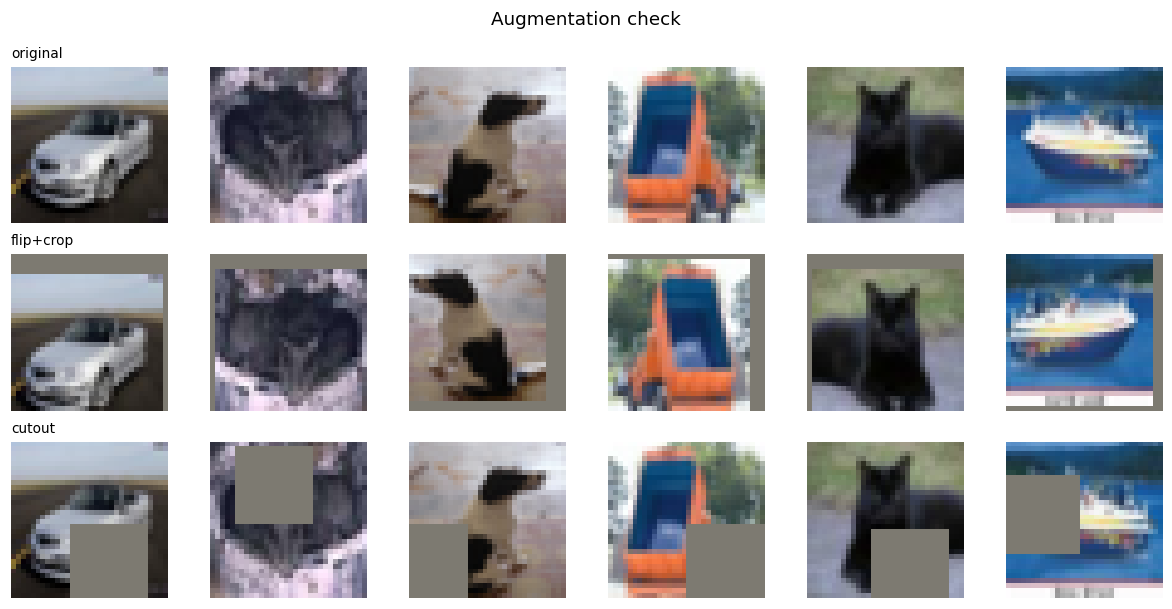

In [12]:
def conv_bn_relu(cin, cout, stride=1):
    return [nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]

class SmallBNCNN(nn.Module):
    def __init__(self, width=32, p_drop=0.0):
        super().__init__()
        layers, cin = [], 3
        for cout in (width, 2 * width, 4 * width):
            layers += conv_bn_relu(cin, cout) + conv_bn_relu(cout, cout) + [nn.MaxPool2d(2)]
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            cin = cout
        self.features = nn.Sequential(*layers)
        self.fc = nn.Linear(cin, 10)
    def forward(self, x):
        return self.fc(self.features(x).mean(dim=(2, 3)))          # global average pooling

# quick visual sanity check of our augmentations (top row: original, then flip+crop, then cutout)
unnorm = lambda t: (t * STD.to(t.device) + MEAN.to(t.device)).clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy()
set_seed(3)
xs = X_tr[:6]
fig, ax = plt.subplots(3, 6, figsize=(11, 5.6))
for r, (title, imgs) in enumerate([("original", xs), ("flip+crop", random_flip_crop(xs)), ("cutout", cutout(xs))]):
    for c in range(6):
        ax[r, c].imshow(unnorm(imgs)[c]); ax[r, c].axis("off")
    ax[r, 0].set_title(title, loc="left", fontsize=9)
plt.suptitle("Augmentation check"); plt.tight_layout(); plt.show()

In [13]:
N_SMALL = CFG["n_small"]
Xs, ys = X_tr[:N_SMALL], y_tr[:N_SMALL]
EP3A = CFG["t3a_epochs"]
configs3a = {
    "baseline":      dict(),
    "weight decay":  dict(wd=1e-3),
    "dropout":       dict(p_drop=0.3),
    "flip+crop":     dict(augment=random_flip_crop),
    "cutout":        dict(augment=cutout),
    "mixup":         dict(mixup_alpha=0.4),
    "all combined":  dict(wd=1e-3, p_drop=0.3, augment=flip_crop_cutout, mixup_alpha=0.4),
}
hist3a = {}
for name, cfg in configs3a.items():
    set_seed()
    model = SmallBNCNN(width=CFG["t3a_width"], p_drop=cfg.get("p_drop", 0.0)).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=cfg.get("wd", 0.0))
    steps = EP3A * (len(Xs) // 128)
    hist3a[name] = fit(model, opt, Xs, ys, X_va, y_va, EP3A, augment=cfg.get("augment"),
                       mixup_alpha=cfg.get("mixup_alpha", 0.0), sched=warmup_cosine(opt, steps), eval_train=True,
                       verbose=False)
    h = hist3a[name]
    print(f"{name:14s} train acc {h['train_acc_clean'][-1]:.3f}  val acc {h['val_acc'][-1]:.3f}  gap {h['train_acc_clean'][-1] - h['val_acc'][-1]:+.3f}")

baseline       train acc 1.000  val acc 0.701  gap +0.299
weight decay   train acc 1.000  val acc 0.709  gap +0.291
dropout        train acc 1.000  val acc 0.731  gap +0.269
flip+crop      train acc 0.987  val acc 0.768  gap +0.219
cutout         train acc 1.000  val acc 0.730  gap +0.270
mixup          train acc 1.000  val acc 0.707  gap +0.293
all combined   train acc 0.783  val acc 0.719  gap +0.064


,train_acc,val_acc,gap,best_val_acc,final_val_loss
config,,,,,
baseline,1.0000,0.7008,0.2992,0.7034,1.3148
weight decay,1.0000,0.7090,0.2910,0.7110,1.0113
dropout,1.0000,0.7310,0.2690,0.7342,0.9721
flip+crop,0.9874,0.7682,0.2192,0.7714,0.8465
cutout,1.0000,0.7304,0.2696,0.7310,1.0880
mixup,1.0000,0.7070,0.2930,0.7094,0.9187
all combined,0.7826,0.7186,0.0640,0.7218,0.8188


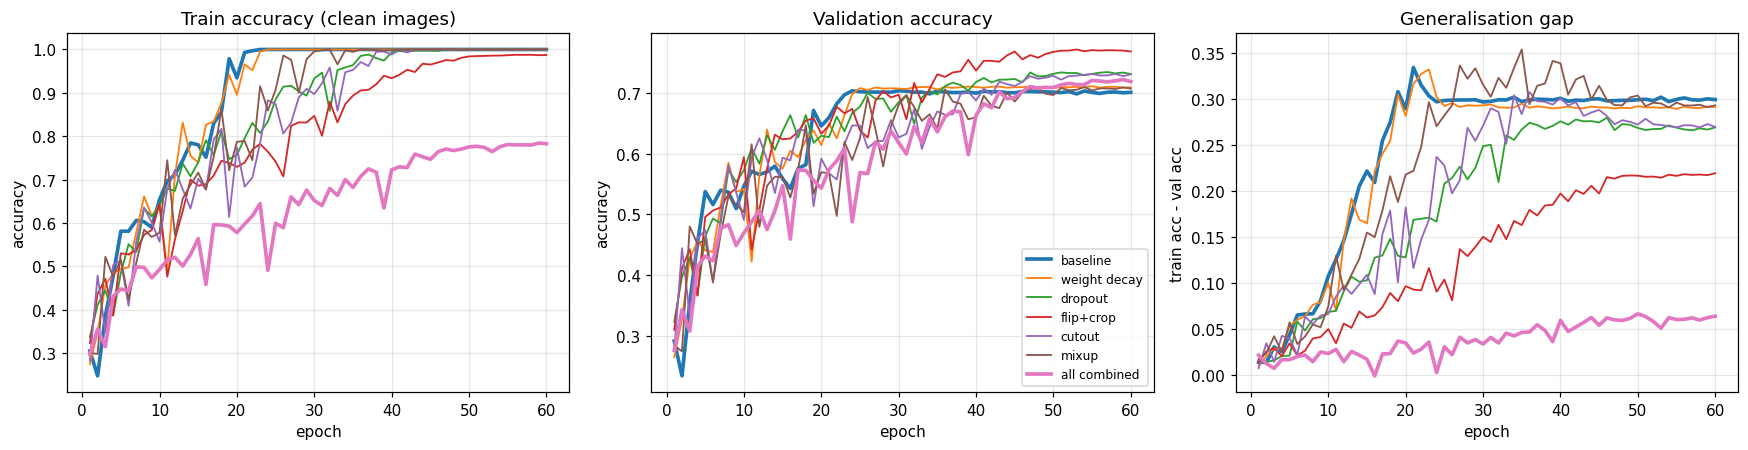

In [14]:
rows = [dict(config=n, train_acc=h["train_acc_clean"][-1], val_acc=h["val_acc"][-1], gap=h["train_acc_clean"][-1] - h["val_acc"][-1],
             best_val_acc=max(h["val_acc"]), final_val_loss=h["val_loss"][-1]) for n, h in hist3a.items()]
df3a = pd.DataFrame(rows).set_index("config")
display(df3a.style.format("{:.4f}").background_gradient(subset=["val_acc"], cmap="Greens"))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for name, h in hist3a.items():
    e = np.arange(1, len(h["val_acc"]) + 1)
    lw = 2.4 if name in ("baseline", "all combined") else 1.2
    ax[0].plot(e, h["train_acc_clean"], lw=lw, label=name)
    ax[1].plot(e, h["val_acc"], lw=lw, label=name)
    ax[2].plot(e, np.array(h["train_acc_clean"]) - np.array(h["val_acc"]), lw=lw, label=name)
ax[0].set(xlabel="epoch", ylabel="accuracy", title="Train accuracy (clean images)")
ax[1].set(xlabel="epoch", ylabel="accuracy", title="Validation accuracy")
ax[2].set(xlabel="epoch", ylabel="train acc - val acc", title="Generalisation gap")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Interpretation (3a)

The baseline reaches 100% train accuracy but only 70.1% validation accuracy, a gap of 29.9 points, so it memorises the 5,000 images. Flip+crop gives the largest validation gain (76.8%, +6.7 points) and the largest gap reduction among the single techniques (21.9 points), because it creates new variants of every image and builds in invariances (small shifts, mirroring) that are valid for natural images. Dropout (73.1%) and cutout (73.0%) give smaller gains of about 3 points. Weight decay (70.9%) and mixup (70.7%) are within noise of the baseline: weight decay has little effect on a batch-norm network (the layers are scale-invariant), and these methods limit capacity or blur labels without adding much new information. All combined has by far the smallest gap (6.4 points), but its validation accuracy (71.9%) is not better than flip+crop alone, because its train accuracy only reaches 78.3%: with this much regularisation the model underfits within the fixed 60 epochs. A lower train accuracy is therefore not a problem in itself, but it does not help if validation accuracy does not improve with it. These are single-seed results; differences below about 1% are not conclusive.

## 3(b) Plain vs. residual networks of depth 6n+2 (8, 20, 56)
CIFAR-style networks (He et al., 2016): a 3×3 conv (16 channels), then **three stages** of $n$ basic blocks with 16 / 32 / 64 channels (the first block of stages 2 and 3 downsamples with stride 2), global average pooling and a linear layer. Depth $=6n+2$, so $n=1,3,9$ for depths 8, 20, 56.
Batch norm everywhere, **Kaiming-normal initialisation** of all conv and linear weights, no dropout, **no data augmentation** (so that the training loss measures how well the network can be *optimised*).
* **Residual** block: $\mathrm{ReLU}(\mathrm{BN}(\mathrm{conv}(\mathrm{ReLU}(\mathrm{BN}(\mathrm{conv}(x)))))+\text{shortcut}(x))$.
* **Plain** block: the same two conv-BN layers and ReLUs but **without** the shortcut term.
* The shortcut is the identity; when the shape changes it is a parameter-free "option A" shortcut (stride-2 subsampling and zero-padding of the new channels), so both families have exactly the same number of parameters.

Training: SGD (momentum 0.9, lr 0.05, weight decay $5\cdot10^{-4}$), batch 128, 1-epoch linear warm-up then cosine decay, identical for all six runs.

In [15]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, stride=1, padding=1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.residual, self.stride, self.extra = residual, stride, cout - cin
    def shortcut(self, x):
        if self.stride != 1 or self.extra != 0:
            x = x[:, :, ::self.stride, ::self.stride]
            x = F.pad(x, (0, 0, 0, 0, self.extra // 2, self.extra - self.extra // 2))   # zero-pad channels
        return x
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)

class CifarNet(nn.Module):
    """Depth = 6n + 2. residual=False gives the 'plain' counterpart (same layers, no shortcut)."""
    def __init__(self, n, residual=True, widths=(16, 32, 64), num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        blocks, cin = [], widths[0]
        for s, w in enumerate(widths):
            for b in range(n):
                blocks.append(BasicBlock(cin, w, 2 if (s > 0 and b == 0) else 1, residual)); cin = w
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():                                     # Kaiming initialisation
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, mode="fan_in", nonlinearity="relu")
                if getattr(m, "bias", None) is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x):
        return self.fc(self.blocks(self.stem(x)).mean(dim=(2, 3)))

# structural checks: depth = 6n+2 weight layers, identical parameter counts for plain / residual
def count_weight_layers(model):
    return sum(isinstance(m, (nn.Conv2d, nn.Linear)) for m in model.modules())
for depth in (8, 20, 56):
    n = (depth - 2) // 6
    p, r = CifarNet(n, residual=False), CifarNet(n, residual=True)
    assert count_weight_layers(p) == depth == count_weight_layers(r) and count_params(p) == count_params(r)
    print(f"depth {depth:2d} (n={n}): weight layers = {count_weight_layers(r)}, parameters plain = residual = {count_params(r):,}")

depth  8 (n=1): weight layers = 8, parameters plain = residual = 75,290
depth 20 (n=3): weight layers = 20, parameters plain = residual = 269,722
depth 56 (n=9): weight layers = 56, parameters plain = residual = 853,018


In [16]:
EP3B = CFG["t3b_epochs"]
hist3b, time3b = {}, {}
for depth in (8, 20, 56):
    n = (depth - 2) // 6
    for residual in (False, True):
        key = (depth, residual)
        set_seed()
        model = CifarNet(n, residual=residual).to(device)
        opt = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9, weight_decay=5e-4)
        steps = EP3B * (len(X_tr) // 128)
        t0 = time.time()
        hist3b[key] = fit(model, opt, X_tr, y_tr, X_va, y_va, EP3B, sched=warmup_cosine(opt, steps, warmup_iters=len(X_tr) // 128),
                          verbose=False)
        time3b[key] = time.time() - t0
        h = hist3b[key]
        print(f"depth {depth:2d} {'residual' if residual else 'plain   '}: final train loss {h['train_loss'][-1]:.3f}  "
              f"val acc {h['val_acc'][-1]:.3f}  ({time3b[key]:.0f}s)")
        del model, opt

depth  8 plain   : final train loss 0.371  val acc 0.795  (53s)
depth  8 residual: final train loss 0.363  val acc 0.794  (55s)
depth 20 plain   : final train loss 0.102  val acc 0.827  (143s)
depth 20 residual: final train loss 0.033  val acc 0.831  (151s)
depth 56 plain   : final train loss 0.574  val acc 0.672  (418s)
depth 56 residual: final train loss 0.006  val acc 0.832  (440s)


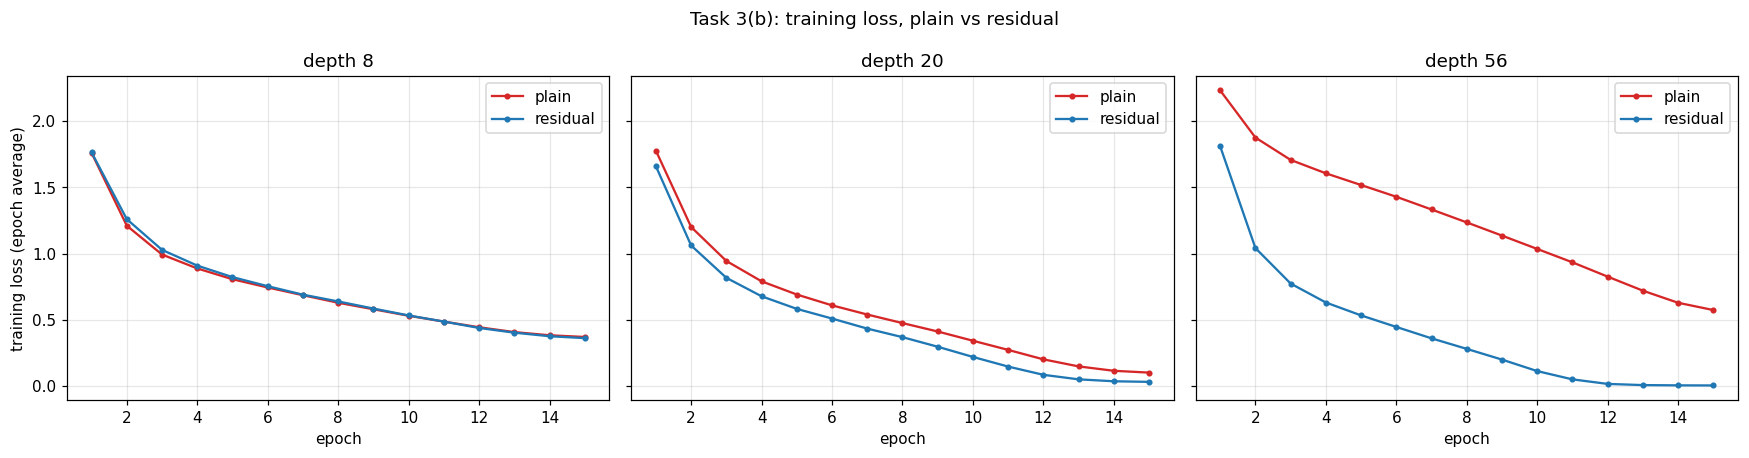

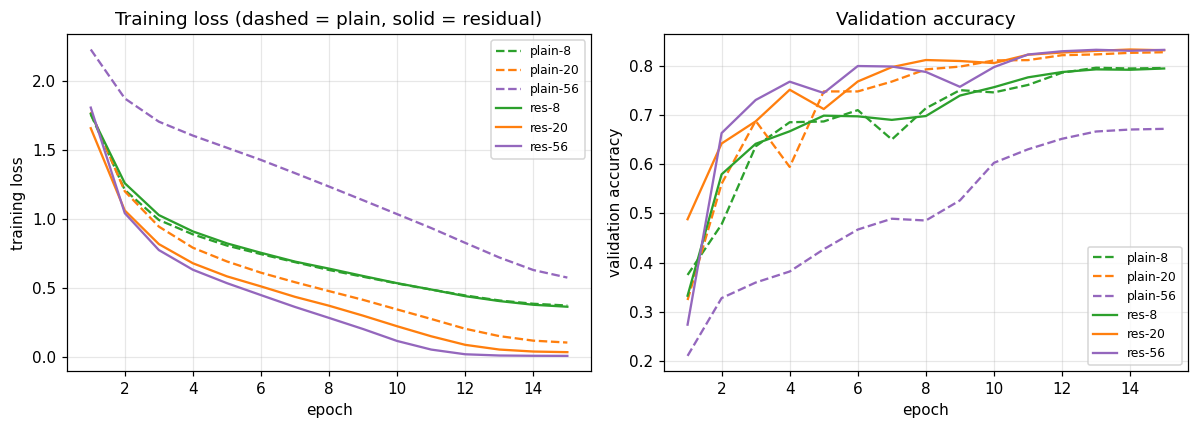

,depth,family,params,final_train_loss,final_val_acc,time_s
0,8,plain,"75,290",0.371,0.7952,53
1,8,residual,"75,290",0.363,0.7942,55
2,20,plain,"269,722",0.102,0.8272,143
3,20,residual,"269,722",0.033,0.8312,151
4,56,plain,"853,018",0.574,0.6716,418
5,56,residual,"853,018",0.006,0.8320,440


In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for a, depth in zip(ax, (8, 20, 56)):
    for residual, c in ((False, "tab:red"), (True, "tab:blue")):
        h = hist3b[(depth, residual)]
        a.plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], "o-", ms=3, color=c, label="residual" if residual else "plain")
    a.set(xlabel="epoch", title=f"depth {depth}"); a.legend()
ax[0].set_ylabel("training loss (epoch average)")
plt.suptitle("Task 3(b): training loss, plain vs residual"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for residual, ls in ((False, "--"), (True, "-")):
    for depth, c in zip((8, 20, 56), ("tab:green", "tab:orange", "tab:purple")):
        h = hist3b[(depth, residual)]
        ax[0].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], ls, color=c, label=f"{'res' if residual else 'plain'}-{depth}")
        ax[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], ls, color=c, label=f"{'res' if residual else 'plain'}-{depth}")
ax[0].set(xlabel="epoch", ylabel="training loss", title="Training loss (dashed = plain, solid = residual)"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="epoch", ylabel="validation accuracy", title="Validation accuracy"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

rows = [dict(depth=d, family="residual" if r else "plain", params=count_params(CifarNet((d - 2) // 6, residual=r)),
             final_train_loss=hist3b[(d, r)]["train_loss"][-1], final_val_acc=hist3b[(d, r)]["val_acc"][-1],
             time_s=time3b[(d, r)]) for d in (8, 20, 56) for r in (False, True)]
display(pd.DataFrame(rows).style.format({"final_train_loss": "{:.3f}", "final_val_acc": "{:.4f}", "time_s": "{:.0f}", "params": "{:,}"}))

### Interpretation (3b)

For the plain nets the final training loss is 0.371 at depth 8, 0.102 at depth 20 and 0.574 at depth 56, so the 56-layer plain network is clearly worse than the 20-layer one on the training set (and its validation accuracy is only 67.2%). This is the degradation problem: it is not overfitting (it is the training loss), and batch norm plus Kaiming initialisation keep the signal scale healthy, but a deeper plain net could represent at least what a shallower one can (the extra layers could be identities) and SGD does not find that solution within the epoch budget. With shortcuts a block computes x + F(x), so doing nothing is easy (F → 0) and the gradient flows through the identity path. The residual training loss decreases with depth (0.363, 0.033, 0.006) and residual-56 reaches 83.2% validation accuracy, against 67.2% for plain-56. The gap between the two families grows with depth: at depth 8 they are almost identical (0.371 vs 0.363), at depth 20 they differ by 0.07, and at depth 56 by 0.57. Both families have exactly the same number of parameters (75,290; 269,722; 853,018), so the difference is caused by the shortcut alone. This is one seed and 15 epochs.

---
# Task 4 (optional): The best CNN with ≤ 500k parameters and ≤ 20 epochs
**Design:** a CIFAR ResNet-32 (n=5, widths 16/32/64, about 0.46M parameters; the same family as 3(b)) trained for 20 epochs with SGD + Nesterov momentum, a one-cycle learning-rate schedule (peak 0.1), weight decay $5\cdot10^{-4}$, label smoothing 0.1 and flip+crop augmentation.
**Ablations** (each trained for the same 20 epochs and judged on the **validation** split): remove the shortcut, remove augmentation, remove weight decay, remove label smoothing, swap SGD for Adam, and use a wider but shallower ResNet-20 (widths 20/40/80).
The design with the best validation accuracy is evaluated on the **test set exactly once** (a guard raises an error if you try to evaluate twice).

In [18]:
T4_EPOCHS = CFG["t4_epochs"]
assert T4_EPOCHS <= 20, "assignment limit: at most 20 epochs"

def build_t4(n=5, widths=(16, 32, 64), residual=True):
    m = CifarNet(n, residual=residual, widths=widths)
    assert count_params(m) <= 500_000, f"too many parameters: {count_params(m):,}"
    return m

def run_t4(name, n=5, widths=(16, 32, 64), residual=True, aug=True, wd=5e-4, label_smoothing=0.1, optim="sgd"):
    set_seed()
    model = build_t4(n, widths, residual).to(device)
    steps = T4_EPOCHS * (len(X_tr) // CFG["t4_batch"])
    if optim == "sgd":
        opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=wd)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=0.1, total_steps=steps, pct_start=0.25)
    else:
        opt = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=wd)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=steps, pct_start=0.25)
    t0 = time.time()
    h = fit(model, opt, X_tr, y_tr, X_va, y_va, T4_EPOCHS, bs=CFG["t4_batch"], augment=random_flip_crop if aug else None,
            label_smoothing=label_smoothing, sched=sched, verbose=False)
    h["time"], h["params"] = time.time() - t0, count_params(model)
    print(f"{name:28s} params {h['params']:>7,}  val acc {h['val_acc'][-1]:.4f}  train loss {h['train_loss'][-1]:.3f}  ({h['time']:.0f}s)")
    return h, {k: v.detach().clone() for k, v in model.state_dict().items()}

t4_variants = {
    "full design (ResNet-32)":     dict(),
    "- shortcut (plain net)":      dict(residual=False),
    "- augmentation":              dict(aug=False),
    "- weight decay":              dict(wd=0.0),
    "- label smoothing":           dict(label_smoothing=0.0),
    "Adam instead of SGD":         dict(optim="adam"),
    "wider ResNet-20 (20/40/80)":  dict(n=3, widths=(20, 40, 80)),
}
t4_hist, t4_state = {}, {}
if RUN_TASK4:
    for name, kw in t4_variants.items():
        t4_hist[name], t4_state[name] = run_t4(name, **kw)

full design (ResNet-32)      params 464,154  val acc 0.9022  train loss 0.662  (330s)
- shortcut (plain net)       params 464,154  val acc 0.8572  train loss 0.771  (315s)
- augmentation               params 464,154  val acc 0.8618  train loss 0.516  (329s)
- weight decay               params 464,154  val acc 0.8872  train loss 0.692  (330s)
- label smoothing            params 464,154  val acc 0.9034  train loss 0.185  (330s)
Adam instead of SGD          params 464,154  val acc 0.8872  train loss 0.690  (331s)
wider ResNet-20 (20/40/80)   params 420,670  val acc 0.9060  train loss 0.661  (242s)


,params,final_val_acc,delta_vs_full,final_train_loss,time_s
variant,,,,,
full design (ResNet-32),"464,154",0.9022,+0.0000,0.662,330
- shortcut (plain net),"464,154",0.8572,-0.0450,0.771,315
- augmentation,"464,154",0.8618,-0.0404,0.516,329
- weight decay,"464,154",0.8872,-0.0150,0.692,330
- label smoothing,"464,154",0.9034,+0.0012,0.185,330
Adam instead of SGD,"464,154",0.8872,-0.0150,0.690,331
wider ResNet-20 (20/40/80),"420,670",0.9060,+0.0038,0.661,242


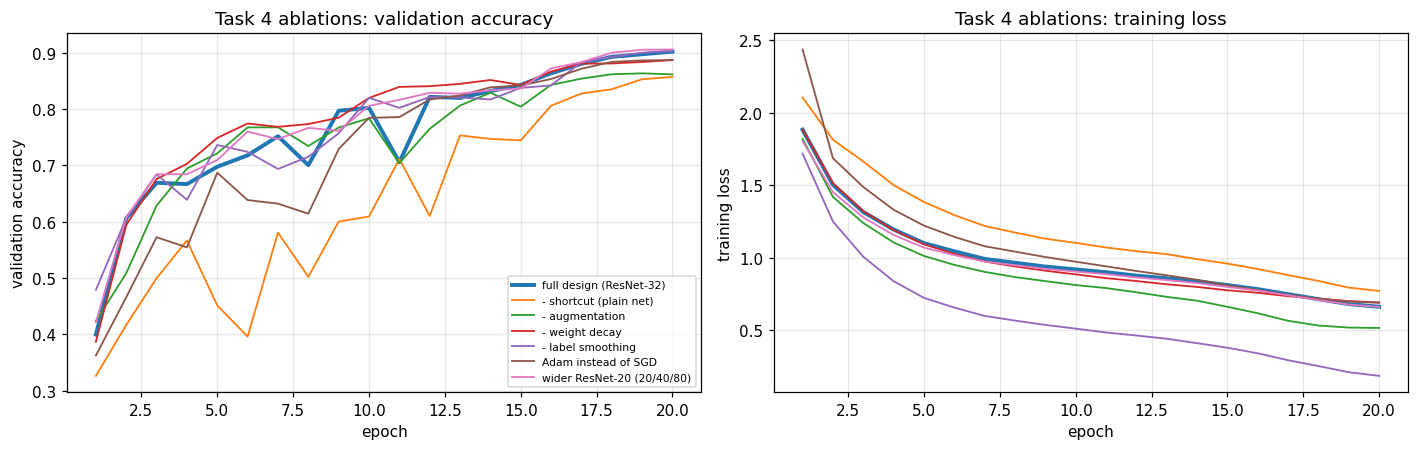

In [19]:
if RUN_TASK4:
    full_val = t4_hist["full design (ResNet-32)"]["val_acc"][-1]
    rows = [dict(variant=n, params=h["params"], final_val_acc=h["val_acc"][-1], delta_vs_full=h["val_acc"][-1] - full_val,
                 final_train_loss=h["train_loss"][-1], time_s=h["time"]) for n, h in t4_hist.items()]
    display(pd.DataFrame(rows).set_index("variant").style.format(
        {"params": "{:,}", "final_val_acc": "{:.4f}", "delta_vs_full": "{:+.4f}", "final_train_loss": "{:.3f}", "time_s": "{:.0f}"}))
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
    for n, h in t4_hist.items():
        lw = 2.6 if n.startswith("full") else 1.2
        ax[0].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], lw=lw, label=n)
        ax[1].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], lw=lw, label=n)
    ax[0].set(xlabel="epoch", ylabel="validation accuracy", title="Task 4 ablations: validation accuracy"); ax[0].legend(fontsize=7)
    ax[1].set(xlabel="epoch", ylabel="training loss", title="Task 4 ablations: training loss")
    plt.tight_layout(); plt.show()

### Interpretation (Task 4 ablations)

The full ResNet-32 design reached 90.22% validation accuracy. Removing the shortcut cost 4.5 points (85.72%), the largest drop: the plain network trains more slowly and erratically (its validation curve is the most unstable and its training loss is higher, 0.771 against 0.662), which agrees with Task 3(b) and shows that the shortcut helps optimisation. Removing augmentation cost 4.0 points (86.18%) while the training loss went down (0.516 against 0.662): without augmentation the model fits the training set more easily but generalises worse. Removing weight decay cost 1.5 points (88.72%) and using Adam instead of SGD also cost 1.5 points (88.72%); both are only a little above the noise level (standard error about 0.4% at 90% accuracy on 5,000 images). Removing label smoothing changed accuracy by +0.12 points (90.34%), which is within noise, so label smoothing did not help here (the much lower training loss, 0.185, is not comparable because smoothing raises the minimum possible loss). The wider but shallower ResNet-20 (20/40/80 channels) was +0.38 points better (90.60%) with fewer parameters (420,670), also within noise, so at this parameter budget the depth and width trade-offs are about equal. The shortcut and the data augmentation mattered most. There is one run per variant.

In [20]:
_TEST_USED = False

def evaluate_on_test_once(model):
    """Loads the CIFAR-10 test set, normalises it with TRAINING statistics, evaluates, and refuses to be called twice."""
    global _TEST_USED
    assert not _TEST_USED, "The test set has already been used once. Restart the kernel to reset (and do not tune on it)."
    _TEST_USED = True
    xt, yt = to_tensor(*load_arrays(train=False))
    Xt, yt = normalize(xt).to(device), yt.to(device)
    return evaluate(model, Xt, yt)

if RUN_TASK4:
    best_name = max(t4_hist, key=lambda n: t4_hist[n]["val_acc"][-1])           # selection uses the VALIDATION split only
    cfg_best = t4_variants[best_name]
    final_model = build_t4(cfg_best.get("n", 5), cfg_best.get("widths", (16, 32, 64)), cfg_best.get("residual", True)).to(device)
    final_model.load_state_dict(t4_state[best_name])
    print(f"Chosen design: {best_name}  ({count_params(final_model):,} parameters, {T4_EPOCHS} epochs, "
          f"validation accuracy {t4_hist[best_name]['val_acc'][-1]:.4f})")
    test_loss, test_acc = evaluate_on_test_once(final_model)
    print(f"TEST accuracy (evaluated once): {test_acc:.4f}   (test loss {test_loss:.3f})")

Chosen design: wider ResNet-20 (20/40/80)  (420,670 parameters, 20 epochs, validation accuracy 0.9060)
TEST accuracy (evaluated once): 0.9012   (test loss 0.352)


### Interpretation (Task 4 result)

The chosen design (wider ResNet-20, 420,670 parameters, 20 epochs) reached 90.60% validation accuracy and 90.12% test accuracy (test loss 0.352), evaluated once on the test set. The 0.5-point drop from validation to test is about the size of the noise, so selecting among 7 variants on the validation split did not overfit it much. The winner beat the full ResNet-32 design by only 0.38 points, which is within noise, so the choice between those two is not conclusive. With more budget I would try longer training, adding mixup and cutout, and an ensemble of several models.

---
## Summary and references
Manual backprop was verified against autograd and finite differences (errors about 1e-16 and 1e-10). The from-scratch MLP overfits at 52% validation accuracy, and vanishing gradients depend mainly on the activation function (sigmoid) rather than the initialisation. Adam, SGD with momentum and plain SGD each need a tuned learning rate (best 75.9% for Adam at 1e-3). On 5k images, flip+crop was the best single regulariser (76.8% against 70.1% for the baseline). Residual connections remove the degradation of deep plain networks (training loss at depth 56: 0.006 against 0.574). In Task 4 the shortcut and data augmentation mattered most in the ablation (about 4 points each), and the final model (wider ResNet-20, 420,670 parameters, 20 epochs) reached 90.12% test accuracy, evaluated once.

**Use of AI tools:** see the acknowledgement at the top of this notebook.

**References**
* K. He, X. Zhang, S. Ren, J. Sun, *Delving Deep into Rectifiers* (Kaiming initialisation), ICCV 2015.
* K. He, X. Zhang, S. Ren, J. Sun, *Deep Residual Learning for Image Recognition*, CVPR 2016.
* D. Kingma, J. Ba, *Adam: A Method for Stochastic Optimization*, ICLR 2015.
* T. DeVries, G. Taylor, *Improved Regularization of Convolutional Neural Networks with Cutout*, 2017.
* H. Zhang, M. Cisse, Y. Dauphin, D. Lopez-Paz, *mixup: Beyond Empirical Risk Minimization*, ICLR 2018.
* S. Ioffe, C. Szegedy, *Batch Normalization*, ICML 2015.